In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Churn_Modelling.csv")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())
df.info()

Number of rows: 10000
Number of columns: 14

Column names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSala

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

Missing values in each column:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Total missing values: 0


In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [8]:
print("Customer Churn Distribution:")
print(df["Exited"].value_counts())
print("\nPercentage Distribution:")
print(df["Exited"].value_counts(normalize=True) * 100)

Customer Churn Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64

Percentage Distribution:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


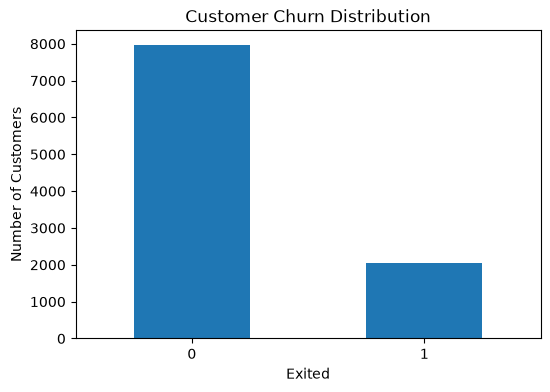

In [9]:
plt.figure(figsize=(6, 4))

df["Exited"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Exited")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

In [10]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [4]:
import pandas as pd

In [5]:
df = pd.read_csv("Churn_Modelling.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (10000, 14)


In [6]:
print("Gender values:")
print(df["Gender"].unique())

Gender values:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str


In [7]:
churn_by_geography = pd.crosstab(
    df["Geography"],
    df["Exited"],
    normalize="index"
) * 100

print(churn_by_geography)

Exited             0          1
Geography                      
France     83.845233  16.154767
Germany    67.556796  32.443204
Spain      83.326605  16.673395


In [9]:
import matplotlib.pyplot as plt

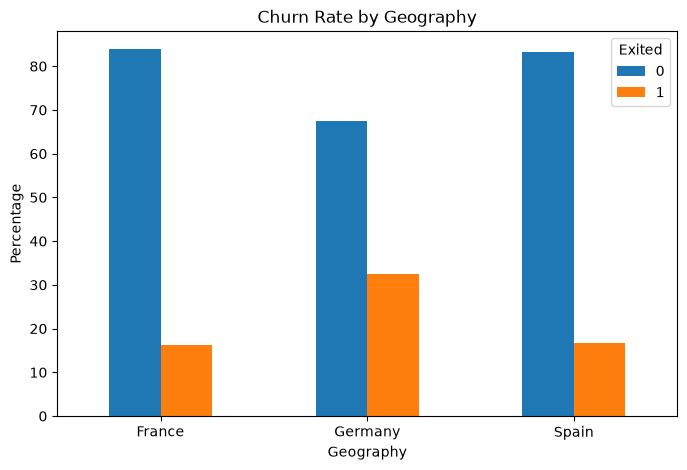

In [10]:
churn_by_geography.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Percentage")
plt.xticks(rotation=0)

plt.show()

In [11]:
print("Gender values:")
print(df["Gender"].unique())

Gender values:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str


In [12]:
churn_by_gender = pd.crosstab(
    df["Gender"],
    df["Exited"],
    normalize="index"
) * 100

print(churn_by_gender)

Exited          0          1
Gender                      
Female  74.928461  25.071539
Male    83.544072  16.455928


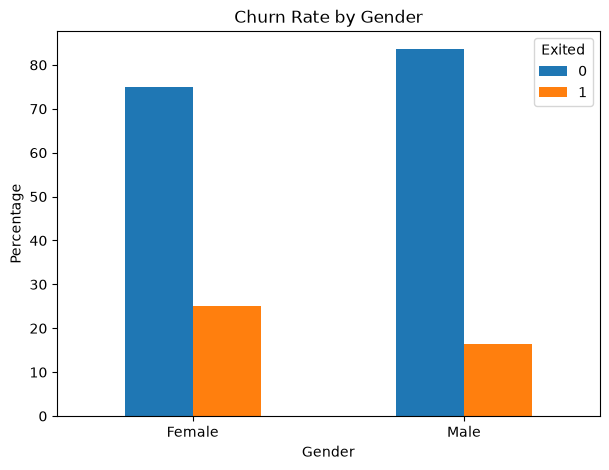

In [13]:
churn_by_gender.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()

In [14]:
numerical_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

print(df.groupby("Exited")[numerical_columns].mean())

        CreditScore        Age    Tenure       Balance  NumOfProducts  \
Exited                                                                  
0        651.853196  37.408389  5.033279  72745.296779       1.544267   
1        645.351497  44.837997  4.932744  91108.539337       1.475209   

        EstimatedSalary  
Exited                   
0          99738.391772  
1         101465.677531  


In [15]:
df_model = df.drop(
    ["RowNumber", "CustomerId", "Surname"],
    axis=1
)

print("Columns after removing unnecessary columns:")
print(df_model.columns)

Columns after removing unnecessary columns:
Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='str')


In [16]:
X = df_model.drop("Exited", axis=1)
y = df_model["Exited"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 10)
Target shape: (10000,)


In [17]:
categorical_features = ["Geography", "Gender"]

print("Categorical features:")
print(categorical_features)

Categorical features:
['Geography', 'Gender']


In [18]:
numerical_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

print("Numerical features:")
print(numerical_features)

Numerical features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 10)
Testing data: (2000, 10)


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [24]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

print("Logistic Regression model created!")

Logistic Regression model created!


In [25]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [26]:
y_pred_logistic = logistic_model.predict(X_test)

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


In [27]:
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic)
logistic_recall = recall_score(y_test, y_pred_logistic)
logistic_f1 = f1_score(y_test, y_pred_logistic)
logistic_roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1 Score :", logistic_f1)
print("ROC-AUC  :", logistic_roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.808
Precision: 0.5891472868217055
Recall   : 0.18673218673218672
F1 Score : 0.2835820895522388
ROC-AUC  : 0.7747578086561138


In [28]:
from sklearn.ensemble import RandomForestClassifier

In [29]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

print("Random Forest model created!")

Random Forest model created!


In [30]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [31]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [32]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("--------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

Random Forest Results
--------------------
Accuracy : 0.8405
Precision: 0.6122448979591837
Recall   : 0.5896805896805897
F1 Score : 0.6007509386733417
ROC-AUC  : 0.8484501450603146


In [33]:
from sklearn.ensemble import GradientBoostingClassifier

In [34]:
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

print("Gradient Boosting model created!")

Gradient Boosting model created!


In [35]:
gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [36]:
y_pred_gb = gradient_boosting_model.predict(X_test)

y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting predictions completed!")

Gradient Boosting predictions completed!


In [37]:
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb)
gb_recall = recall_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)
gb_roc_auc = roc_auc_score(y_test, y_prob_gb)

print("Gradient Boosting Results")
print("------------------------")
print("Accuracy :", gb_accuracy)
print("Precision:", gb_precision)
print("Recall   :", gb_recall)
print("F1 Score :", gb_f1)
print("ROC-AUC  :", gb_roc_auc)

Gradient Boosting Results
------------------------
Accuracy : 0.869
Precision: 0.7821011673151751
Recall   : 0.49385749385749383
F1 Score : 0.6054216867469879
ROC-AUC  : 0.8702176753024209


In [38]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        gb_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision,
        gb_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall,
        gb_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1,
        gb_f1
    ],
    "ROC-AUC": [
        logistic_roc_auc,
        rf_roc_auc,
        gb_roc_auc
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8080,0.589147,0.186732,0.283582,0.774758
1,Random Forest,0.8405,0.612245,0.589681,0.600751,0.848450
2,Gradient Boosting,0.8690,0.782101,0.493857,0.605422,0.870218


In [39]:
results_rounded = results.copy()

results_rounded.iloc[:, 1:] = results_rounded.iloc[:, 1:].round(4)

results_rounded

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8080,0.5891,0.1867,0.2836,0.7748
1,Random Forest,0.8405,0.6122,0.5897,0.6008,0.8485
2,Gradient Boosting,0.8690,0.7821,0.4939,0.6054,0.8702


In [40]:
best_model_name = results.loc[
    results["F1 Score"].idxmax(),
    "Model"
]

print("Best Model based on F1 Score:")
print(best_model_name)

Best Model based on F1 Score:
Gradient Boosting


In [41]:
best_roc_model = results.loc[
    results["ROC-AUC"].idxmax(),
    "Model"
]

print("Best Model based on ROC-AUC:")
print(best_roc_model)

Best Model based on ROC-AUC:
Gradient Boosting


In [42]:
print("===== MODEL COMPARISON =====")
print(results_rounded.to_string(index=False))

===== MODEL COMPARISON =====
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.8080     0.5891  0.1867    0.2836   0.7748
      Random Forest    0.8405     0.6122  0.5897    0.6008   0.8485
  Gradient Boosting    0.8690     0.7821  0.4939    0.6054   0.8702


In [43]:
if best_model_name == "Logistic Regression":
    best_model = logistic_model
    best_predictions = y_pred_logistic
elif best_model_name == "Random Forest":
    best_model = random_forest_model
    best_predictions = y_pred_rf
else:
    best_model = gradient_boosting_model
    best_predictions = y_pred_gb

print("Selected Best Model:", best_model_name)

Selected Best Model: Gradient Boosting


In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, best_predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1537   56]
 [ 206  201]]


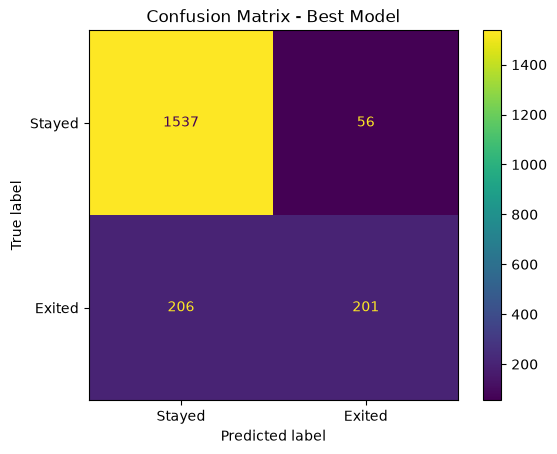

In [45]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Exited"]
)

disp.plot()
plt.title("Confusion Matrix - Best Model")
plt.show()

In [46]:
from sklearn.metrics import classification_report

print("Classification Report")
print("---------------------")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Stayed", "Exited"]
))

Classification Report
---------------------
              precision    recall  f1-score   support

      Stayed       0.88      0.96      0.92      1593
      Exited       0.78      0.49      0.61       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000



In [47]:
best_row = results[
    results["Model"] == best_model_name
].iloc[0]

print("===== FINAL MODEL PERFORMANCE =====")
print("Best Model :", best_model_name)
print("Accuracy   :", round(best_row["Accuracy"], 4))
print("Precision  :", round(best_row["Precision"], 4))
print("Recall     :", round(best_row["Recall"], 4))
print("F1 Score   :", round(best_row["F1 Score"], 4))
print("ROC-AUC    :", round(best_row["ROC-AUC"], 4))

===== FINAL MODEL PERFORMANCE =====
Best Model : Gradient Boosting
Accuracy   : 0.869
Precision  : 0.7821
Recall     : 0.4939
F1 Score   : 0.6054
ROC-AUC    : 0.8702


In [48]:
import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [49]:
joblib.dump(
    best_model,
    "customer_churn_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [50]:
results_rounded.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [51]:
import os

print("Saved files:")
print(os.listdir())

Saved files:
['.ipynb_checkpoints', 'Churn_Modelling.csv', 'customer_churn_model.pkl', 'customer_churn_prediction.ipynb', 'model_comparison.csv']


In [52]:
loaded_model = joblib.load(
    "customer_churn_model.pkl"
)

test_predictions = loaded_model.predict(X_test)

print("Saved model loaded successfully!")
print("Verification Accuracy:",
      accuracy_score(y_test, test_predictions))

Saved model loaded successfully!
Verification Accuracy: 0.869


In [53]:
new_customer = pd.DataFrame({
    "CreditScore": [650],
    "Geography": ["France"],
    "Gender": ["Female"],
    "Age": [35],
    "Tenure": [5],
    "Balance": [75000],
    "NumOfProducts": [1],
    "HasCrCard": [1],
    "IsActiveMember": [1],
    "EstimatedSalary": [60000]
})

print(new_customer)

   CreditScore Geography  Gender  Age  Tenure  Balance  NumOfProducts  \
0          650    France  Female   35       5    75000              1   

   HasCrCard  IsActiveMember  EstimatedSalary  
0          1               1            60000  


In [54]:
prediction = loaded_model.predict(new_customer)

if prediction[0] == 1:
    print("Prediction: Customer is likely to CHURN.")
else:
    print("Prediction: Customer is likely to STAY.")

Prediction: Customer is likely to STAY.


In [55]:
probability = loaded_model.predict_proba(new_customer)[0][1]

print("Churn Probability:", round(probability * 100, 2), "%")

Churn Probability: 10.16 %


In [56]:
if prediction[0] == 1:
    result = "Likely to Churn"
else:
    result = "Likely to Stay"

print("===== CUSTOMER CHURN PREDICTION =====")
print("Customer Age       :", new_customer["Age"].iloc[0])
print("Geography          :", new_customer["Geography"].iloc[0])
print("Gender             :", new_customer["Gender"].iloc[0])
print("Churn Probability  :", round(probability * 100, 2), "%")
print("Final Prediction   :", result)

===== CUSTOMER CHURN PREDICTION =====
Customer Age       : 35
Geography          : France
Gender             : Female
Churn Probability  : 10.16 %
Final Prediction   : Likely to Stay


In [57]:
prediction_result = new_customer.copy()

prediction_result["Churn Probability"] = round(
    probability * 100, 2
)

prediction_result["Prediction"] = result

prediction_result.to_csv(
    "new_customer_prediction.csv",
    index=False
)

print("Prediction result saved successfully!")

Prediction result saved successfully!


In [58]:
project_summary = {
    "Project": "Customer Churn Prediction",
    "Dataset": "Churn_Modelling.csv",
    "Target": "Exited",
    "Models": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Best Model": best_model_name,
    "Accuracy": round(best_row["Accuracy"], 4),
    "Precision": round(best_row["Precision"], 4),
    "Recall": round(best_row["Recall"], 4),
    "F1 Score": round(best_row["F1 Score"], 4),
    "ROC-AUC": round(best_row["ROC-AUC"], 4)
}

print(project_summary)

{'Project': 'Customer Churn Prediction', 'Dataset': 'Churn_Modelling.csv', 'Target': 'Exited', 'Models': ['Logistic Regression', 'Random Forest', 'Gradient Boosting'], 'Best Model': 'Gradient Boosting', 'Accuracy': np.float64(0.869), 'Precision': np.float64(0.7821), 'Recall': np.float64(0.4939), 'F1 Score': np.float64(0.6054), 'ROC-AUC': np.float64(0.8702)}


In [59]:
import json

with open("project_summary.json", "w") as file:
    json.dump(project_summary, file, indent=4)

print("Project summary saved successfully!")

Project summary saved successfully!


In [60]:
requirements = """pandas
numpy
matplotlib
scikit-learn
joblib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [61]:
print("===== TASK 3 PROJECT FILES =====")

project_files = [
    file for file in os.listdir()
    if file.endswith((".ipynb", ".csv", ".pkl", ".json", ".txt"))
]

for file in project_files:
    print(file)

===== TASK 3 PROJECT FILES =====
Churn_Modelling.csv
customer_churn_model.pkl
customer_churn_prediction.ipynb
model_comparison.csv
new_customer_prediction.csv
project_summary.json
requirements.txt


In [62]:
required_files = [
    "customer_churn_model.pkl",
    "model_comparison.csv",
    "new_customer_prediction.csv",
    "project_summary.json",
    "requirements.txt"
]

print("===== PROJECT CHECK =====")

for file in required_files:
    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗", file)

print("\nTask 3 ML implementation completed successfully!")

===== PROJECT CHECK =====
✓ customer_churn_model.pkl
✓ model_comparison.csv
✓ new_customer_prediction.csv
✓ project_summary.json
✓ requirements.txt

Task 3 ML implementation completed successfully!


In [64]:
readme_content = """# Customer Churn Prediction

## Project Overview

Customer Churn Prediction is a Machine Learning project that predicts whether a customer is likely to leave a company based on customer information and behavior.

The project uses the Churn Modelling dataset and compares three Machine Learning algorithms:

- Logistic Regression
- Random Forest
- Gradient Boosting

## Dataset

The dataset contains 10,000 customer records with information such as:

- Credit Score
- Geography
- Gender
- Age
- Tenure
- Balance
- Number of Products
- Credit Card Status
- Active Membership Status
- Estimated Salary

The target variable is `Exited`.

- `0` = Customer stayed
- `1` = Customer exited

## Project Workflow

1. Load the dataset
2. Explore the data
3. Check missing values and duplicates
4. Perform exploratory data analysis
5. Remove unnecessary columns
6. Encode categorical features
7. Scale numerical features
8. Split data into training and testing sets
9. Train Machine Learning models
10. Evaluate the models
11. Select the best-performing model
12. Save the trained model
13. Predict churn for a new customer

## Machine Learning Models

### Logistic Regression
Used as a baseline classification model.

### Random Forest
An ensemble learning algorithm that combines multiple decision trees.

### Gradient Boosting
An ensemble technique that builds models sequentially to improve prediction performance.

## Evaluation Metrics

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

## Best Model

The best model is selected based on the highest F1 Score.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Joblib
- Jupyter Notebook

## Project Files

- `customer_churn_prediction.ipynb` - Complete Jupyter Notebook
- `customer_churn_model.pkl` - Trained best model
- `model_comparison.csv` - Model performance comparison
- `new_customer_prediction.csv` - Sample prediction
- `project_summary.json` - Project performance summary
- `requirements.txt` - Required Python libraries

## Sample Prediction

The trained model can predict whether a new customer is likely to churn and also provide the probability of churn.

## Conclusion

This project demonstrates how Machine Learning can be used to identify customers who are likely to churn. Such predictions can help businesses identify at-risk customers and take suitable retention actions.
"""

print("README content created successfully!")

README content created successfully!


In [65]:
with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [66]:
print("README.md exists:", os.path.exists("README.md"))

with open("README.md", "r", encoding="utf-8") as file:
    print(file.read()[:1000])

README.md exists: True
# Customer Churn Prediction

## Project Overview

Customer Churn Prediction is a Machine Learning project that predicts whether a customer is likely to leave a company based on customer information and behavior.

The project uses the Churn Modelling dataset and compares three Machine Learning algorithms:

- Logistic Regression
- Random Forest
- Gradient Boosting

## Dataset

The dataset contains 10,000 customer records with information such as:

- Credit Score
- Geography
- Gender
- Age
- Tenure
- Balance
- Number of Products
- Credit Card Status
- Active Membership Status
- Estimated Salary

The target variable is `Exited`.

- `0` = Customer stayed
- `1` = Customer exited

## Project Workflow

1. Load the dataset
2. Explore the data
3. Check missing values and duplicates
4. Perform exploratory data analysis
5. Remove unnecessary columns
6. Encode categorical features
7. Scale numerical features
8. Split data into training and testing sets
9. Train Machine Learni

In [67]:
print("===== FINAL PROJECT FILES =====")

for file in sorted(os.listdir()):
    if file.endswith((
        ".ipynb",
        ".csv",
        ".pkl",
        ".json",
        ".txt",
        ".md"
    )):
        print(file)

===== FINAL PROJECT FILES =====
Churn_Modelling.csv
README.md
customer_churn_model.pkl
customer_churn_prediction.ipynb
model_comparison.csv
new_customer_prediction.csv
project_summary.json
requirements.txt


In [69]:
print("=" * 50)
print("CODSOFT TASK 3 - CUSTOMER CHURN PREDICTION")
print("=" * 50)
print("✓ Data preprocessing completed")
print("✓ Exploratory analysis completed")
print("✓ Logistic Regression trained")
print("✓ Random Forest trained")
print("✓ Gradient Boosting trained")
print("✓ Models compared")
print("✓ Best model selected")
print("✓ Model saved")
print("✓ Sample prediction completed")
print("✓ README created")
print("=" * 50)

print("=" * 50)

CODSOFT TASK 3 - CUSTOMER CHURN PREDICTION
✓ Data preprocessing completed
✓ Exploratory analysis completed
✓ Logistic Regression trained
✓ Random Forest trained
✓ Gradient Boosting trained
✓ Models compared
✓ Best model selected
✓ Model saved
✓ Sample prediction completed
✓ README created


In [70]:
import os

notebooks = [
    file for file in os.listdir()
    if file.endswith(".ipynb")
]

print("Jupyter Notebooks:")
for file in notebooks:
    print("✓", file)

Jupyter Notebooks:
✓ customer_churn_prediction.ipynb


In [71]:
required_files = [
    "customer_churn_model.pkl",
    "model_comparison.csv",
    "new_customer_prediction.csv",
    "project_summary.json",
    "requirements.txt",
    "README.md"
]

print("Required files:")
for file in required_files:
    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗ MISSING:", file)

Required files:
✓ customer_churn_model.pkl
✓ model_comparison.csv
✓ new_customer_prediction.csv
✓ project_summary.json
✓ requirements.txt
✓ README.md


In [72]:
print("===== MODEL PERFORMANCE =====")

print(
    results_rounded.to_string(index=False)
)

===== MODEL PERFORMANCE =====
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.8080     0.5891  0.1867    0.2836   0.7748
      Random Forest    0.8405     0.6122  0.5897    0.6008   0.8485
  Gradient Boosting    0.8690     0.7821  0.4939    0.6054   0.8702


In [73]:
print("===== SAVED MODEL CHECK =====")

print("Model file exists:",
      os.path.exists("customer_churn_model.pkl"))

print("Selected model:",
      best_model_name)

print("Model type:",
      type(best_model).__name__)

===== SAVED MODEL CHECK =====
Model file exists: True
Selected model: Gradient Boosting
Model type: Pipeline


In [75]:
all_files_present = all(
    os.path.exists(file)
    for file in required_files
)

print("=" * 50)

if all_files_present:
    print("✓ ALL REQUIRED FILES ARE PRESENT")
    print("✓ MODEL IS SAVED")
    print("✓ RESULTS ARE SAVED")
    print("✓ README IS PRESENT")
   
else:
    print("Some files are missing.")
    print("Please check Cell 62.")

print("=" * 50)

✓ ALL REQUIRED FILES ARE PRESENT
✓ MODEL IS SAVED
✓ RESULTS ARE SAVED
✓ README IS PRESENT


In [76]:
import os

print("Current Jupyter folder:")
print(os.getcwd())

Current Jupyter folder:
C:\Users\Pranjali\CODSOFT_TASK3


In [77]:
notebooks = [
    file for file in os.listdir()
    if file.endswith(".ipynb")
]

print("Notebook files found:")

for file in notebooks:
    print(file)

Notebook files found:
customer_churn_prediction.ipynb


In [78]:
task3_folder = r"C:\Users\Pranjali\CODSOFT_TASK3"

print("Task 3 folder exists:",
      os.path.exists(task3_folder))

if os.path.exists(task3_folder):
    print("\nFiles inside CODSOFT_TASK3:")
    for file in os.listdir(task3_folder):
        print(file)

Task 3 folder exists: True

Files inside CODSOFT_TASK3:
.ipynb_checkpoints
Churn_Modelling.csv
customer_churn_model.pkl
customer_churn_prediction.ipynb
model_comparison.csv
new_customer_prediction.csv
project_summary.json
README.md
requirements.txt


In [80]:
import os

notebook_path = r"C:\Users\Pranjali\CODSOFT_TASK3\customer_churn_prediction.ipynb"

print("Notebook saved:", os.path.exists(notebook_path))

Notebook saved: True
